# Airline Tweets: Cleaning, EDA and Feature Engineering

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

## 2. Load the data

In [2]:
df = pd.read_csv("Tweets.csv")
print("Original shape:", df.shape)

df = df[["text", "airline_sentiment"]].copy()
df.columns = ["text", "label"]
df.head()

Original shape: (14640, 15)


,text,label
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


## 3. Inspect the data

In [3]:
print("Selected shape:", df.shape)
df.info()

Selected shape: (14640, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    14640 non-null  object
 1   label   14640 non-null  object
dtypes: object(2)
memory usage: 228.9+ KB


In [4]:
df.describe(include="all")

,text,label
count,14640,14640
unique,14427,3
top,@united thanks,negative
freq,6,9178


In [5]:
df["label"].value_counts()

,count
label,
negative,9178
neutral,3099
positive,2363


## 4. Check missing values and duplicates

In [6]:
print("Missing values before cleaning:")
print(df.isna().sum())
print("Extra exact duplicate rows:", df.duplicated().sum())
print("Rows in repeated-text groups:", df.duplicated(subset="text", keep=False).sum())
rows_before = len(df)

Missing values before cleaning:
text     0
label    0
dtype: int64
Extra exact duplicate rows: 188
Rows in repeated-text groups: 400


In [7]:
df = df.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].str.strip()
print("Blank messages:", (df["text"] == "").sum())
df = df[df["text"] != ""].copy()
print("Rows after missing/blank handling:", len(df))

Blank messages: 0
Rows after missing/blank handling: 14640


In [8]:
# labels_per_text = df.groupby("text")["label"].nunique()
# print("Texts with conflicting labels:", (labels_per_text > 1).sum())
# print("Rows in repeated-text groups:", df.duplicated(subset="text", keep=False).sum())

In [9]:
df = df.drop_duplicates(subset="text", keep=False).copy()

print("Rows before:", rows_before)
print("Rows after:", len(df))
print("Rows removed:", rows_before - len(df))
print("Missing values after cleaning:")
print(df.isna().sum())
print("Exact duplicates after cleaning:", df.duplicated().sum())
print("Repeated texts after cleaning:", df.duplicated(subset="text").sum())
print(df["label"].value_counts())

Rows before: 14640
Rows after: 14240
Rows removed: 400
Missing values after cleaning:
text     0
label    0
dtype: int64
Exact duplicates after cleaning: 0
Repeated texts after cleaning: 0
label
negative    8988
neutral     3017
positive    2235
Name: count, dtype: int64


## 5. Create new features

In [10]:
df["tweet_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()
df["mention_count"] = df["text"].str.count("@")
df["hashtag_count"] = df["text"].str.count("#")

df.head()

,text,label,tweet_length,word_count,mention_count,hashtag_count
0,@VirginAmerica What @dhepburn said.,neutral,35,4,2,0
1,@VirginAmerica plus you've added commercials t...,positive,72,9,1,0
2,@VirginAmerica I didn't today... Must mean I n...,neutral,71,12,1,0
3,@VirginAmerica it's really aggressive to blast...,negative,126,17,1,0
4,@VirginAmerica and it's a really big bad thing...,negative,55,10,1,0


In [11]:
df[["tweet_length", "word_count", "mention_count", "hashtag_count"]].describe()

,tweet_length,word_count,mention_count,hashtag_count
count,14240.000000,14240.000000,14240.000000,14240.000000
mean,104.356812,17.756671,1.133497,0.251053
std,35.755885,6.798071,0.412191,0.665562
min,12.000000,2.000000,1.000000,0.000000
25%,78.000000,13.000000,1.000000,0.000000
50%,115.000000,19.000000,1.000000,0.000000
75%,136.000000,23.000000,1.000000,0.000000
max,186.000000,36.000000,6.000000,8.000000


In [12]:
df.groupby("label")[["tweet_length", "word_count", "mention_count", "hashtag_count"]].mean().round(2)

,tweet_length,word_count,mention_count,hashtag_count
label,,,,
negative,113.93,19.69,1.12,0.24
neutral,87.73,14.47,1.18,0.22
positive,88.31,14.40,1.15,0.31


## 6. Check length outliers using IQR

In [13]:
Q1 = df["tweet_length"].quantile(0.25)
Q3 = df["tweet_length"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["length_outlier"] = (df["tweet_length"] < lower) | (df["tweet_length"] > upper)

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Length outliers:", df["length_outlier"].sum())
df[df["length_outlier"]][["text", "label", "tweet_length"]].head()

Lower limit: -9.0
Upper limit: 223.0
Length outliers: 0


,text,label,tweet_length


## 7. EDA charts

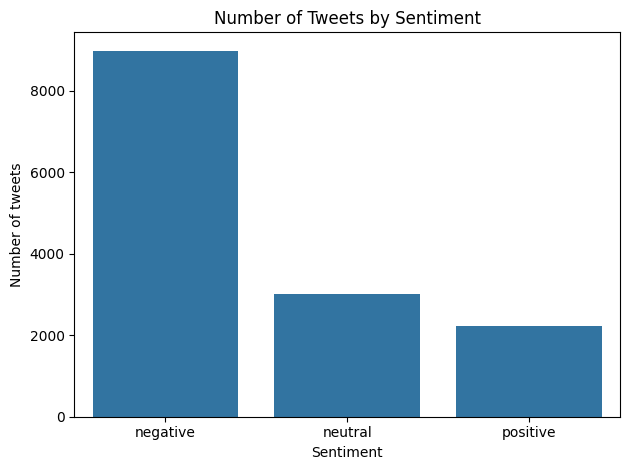

In [14]:
sns.countplot(data=df, x="label", order=["negative", "neutral", "positive"])
plt.title("Number of Tweets by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of tweets")
plt.tight_layout()
plt.show()

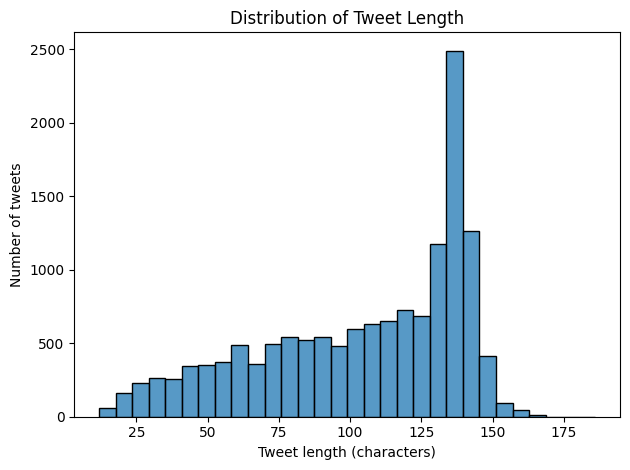

In [15]:
sns.histplot(data=df, x="tweet_length", bins=30)
plt.title("Distribution of Tweet Length")
plt.xlabel("Tweet length (characters)")
plt.ylabel("Number of tweets")
plt.tight_layout()
plt.show()

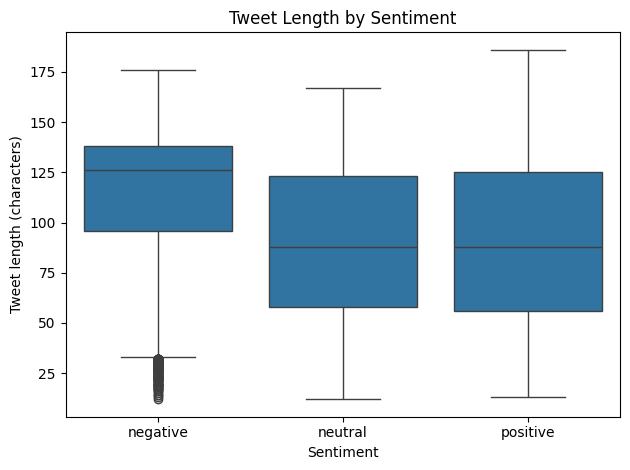

In [16]:
sns.boxplot(data=df, x="label", y="tweet_length", order=["negative", "neutral", "positive"])
plt.title("Tweet Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Tweet length (characters)")
plt.tight_layout()
plt.show()

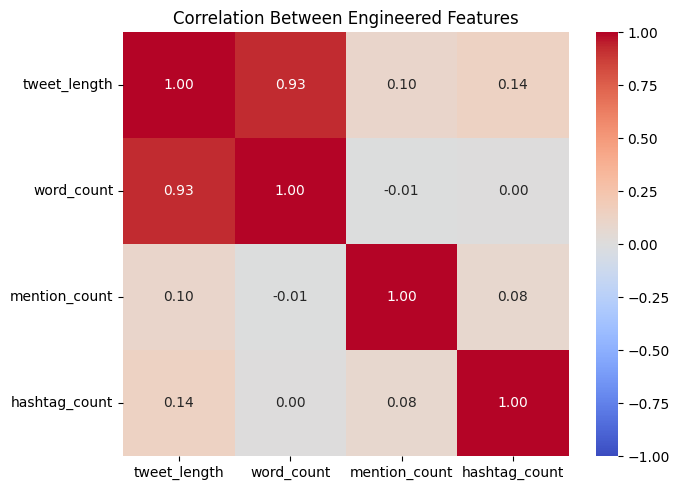

In [17]:
features = df[["tweet_length", "word_count", "mention_count", "hashtag_count"]]

plt.figure(figsize=(7, 5))
sns.heatmap(features.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Engineered Features")
plt.tight_layout()
plt.show()

## 9. LSTM

In [18]:
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

keras.utils.set_random_seed(42)

In [19]:
le = LabelEncoder()
df["label_code"] = le.fit_transform(df["label"])

X = df["text"]
y = df["label_code"]
n_classes = len(le.classes_)

print("Classes:", le.classes_)
print("Number of classes:", n_classes)

Classes: ['negative' 'neutral' 'positive']
Number of classes: 3


Split the data

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Tokenize using 5,000 as the vocabulary limit

In [21]:
vocab_size = 5000

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

Pad or truncate every sequence to 50 tokens

In [22]:
max_len = 50

X_train = pad_sequences(X_train, maxlen=max_len)
X_test = pad_sequences(X_test, maxlen=max_len)

Build the LSTM model

In [23]:
model = Sequential([
    Input(shape=(max_len,)),
    Embedding(input_dim=vocab_size, output_dim=32),
    LSTM(32),
    Dense(n_classes, activation="softmax")
])

Compile the model

In [24]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Train for 5 epochs

In [25]:
history = model.fit(
    X_train, y_train, epochs=5, batch_size=100, verbose=2
)

Epoch 1/5
114/114 - 5s - 43ms/step - accuracy: 0.6662 - loss: 0.7929
Epoch 2/5
114/114 - 5s - 45ms/step - accuracy: 0.7709 - loss: 0.5671
Epoch 3/5
114/114 - 3s - 27ms/step - accuracy: 0.8347 - loss: 0.4315
Epoch 4/5
114/114 - 3s - 26ms/step - accuracy: 0.8733 - loss: 0.3427
Epoch 5/5
114/114 - 6s - 51ms/step - accuracy: 0.8981 - loss: 0.2875


Report test accuracy

In [26]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

Test Loss: 0.6031
Test Accuracy: 78.34 %


## What does the forget gate do?
The forget gate lets an LSTM learn how much of its previous cell memory to keep or discard at each step. A plain RNN has no separate cell memory or explicit forget gate, making selective long-term retention harder.

The three classes use Softmax with sparse categorical crossentropy because the encoded labels are integers. The forget gate lets the LSTM selectively retain or discard previous cell memory, helping it carry useful information across many tokens.

**Executed model result:** After 5 epochs, test accuracy is **78.34%**, with finite test loss **0.6031**. This is a result on one stratified 80/20 split; results may vary slightly between runs.